# Transaction Data Clustering

Dicoding machine learning assignment — original analysis and saved outputs.


## Dataset Overview


## 1. Import Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer
import joblib

## 2. Load Dataset & Exploratory Data Analysis


In [2]:
# Load data


url='https://docs.google.com/spreadsheets/d/e/2PACX-1vTbg5WVW6W3c8SPNUGc3A3AL-AG32TPEQGpdzARfNICMsLFI0LQj0jporhsLCeVhkN5AoRsTkn08AYl/pub?output=csv'
df = pd.read_csv(url)



In [3]:


df.head()



,TransactionID,AccountID,TransactionAmount,PreviousTransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,198.0,1.0,7429.40,2024-11-04 08:06:39


In [4]:
# Tinjau jumlah baris kolom dan jenis data dalam dataset dengan info.


df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2508 non-null   object 
 1   AccountID                2516 non-null   object 
 2   TransactionAmount        2511 non-null   float64
 3   PreviousTransactionDate  2509 non-null   object 
 4   TransactionType          2507 non-null   object 
 5   Location                 2507 non-null   object 
 6   DeviceID                 2507 non-null   object 
 7   IP Address               2517 non-null   object 
 8   MerchantID               2514 non-null   object 
 9   Channel                  2510 non-null   object 
 10  CustomerAge              2519 non-null   float64
 11  CustomerOccupation       2514 non-null   object 
 12  TransactionDuration      2511 non-null   float64
 13  LoginAttempts            2516 non-null   float64
 14  AccountBalance          

In [5]:
# Menampilkan statistik deskriptif dataset dengan menjalankan describe


df.describe()



,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2511.000000,2519.000000,2511.000000,2516.000000,2510.000000
mean,297.656468,44.678444,119.422939,1.121622,5113.438124
std,292.230367,17.837359,70.078513,0.594469,3897.975861
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.310000,27.000000,63.000000,1.000000,1504.727500
50%,211.360000,45.000000,112.000000,1.000000,4734.110000
75%,413.105000,59.000000,161.000000,1.000000,7672.687500
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


In [6]:
# Memilih kolom numerik
numerical_cols = df.select_dtypes(include=['number']).columns

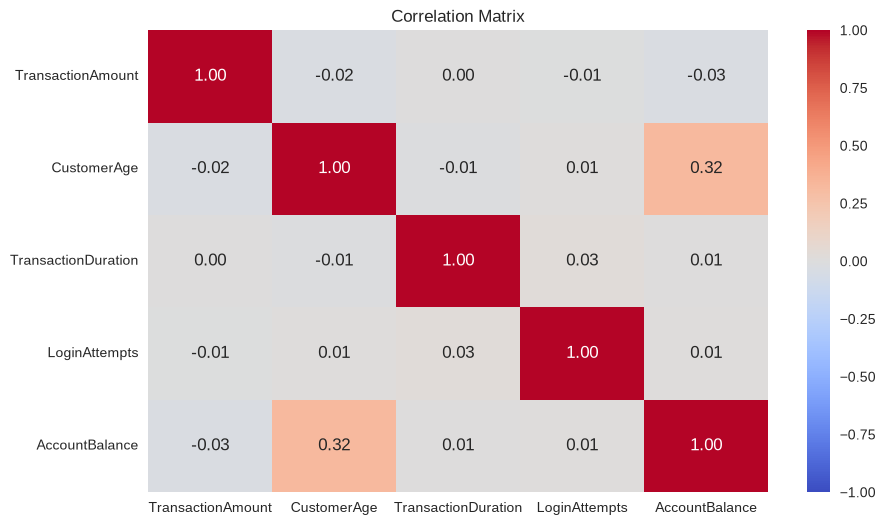

In [7]:
# Menampilkan korelasi antar fitur (Opsional Skilled 1)


# Hitung matriks korelasi
correlation = df[numerical_cols].corr()

# Buat visualisasi heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation,
               annot=True,
               cmap='coolwarm',
               fmt=".2f",
               vmin=-1,
               vmax=1)
plt.title('Correlation Matrix')
plt.show()



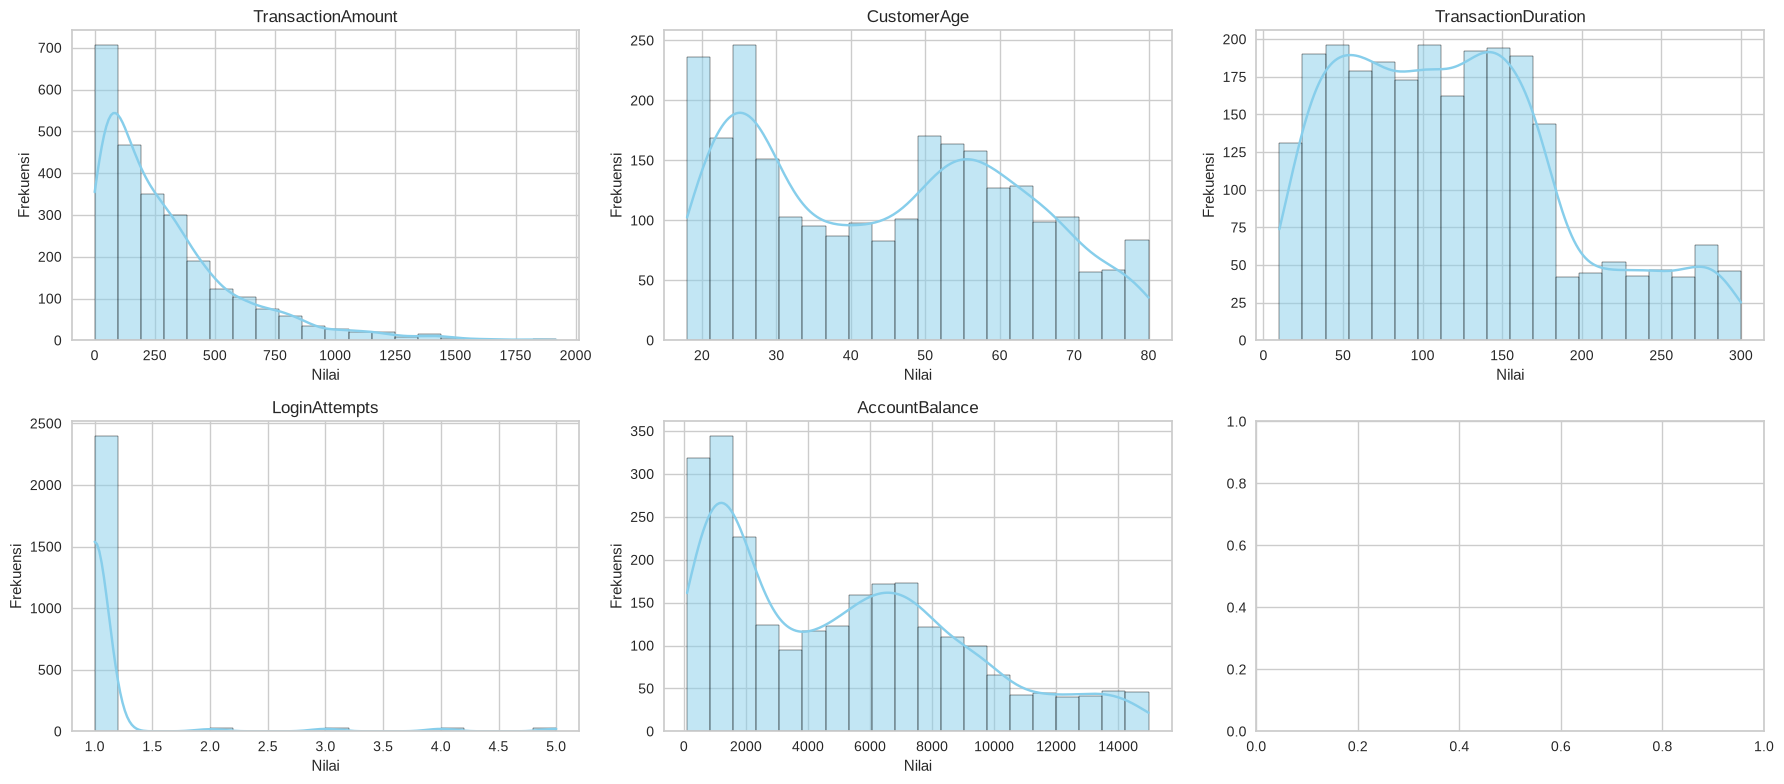

In [8]:
# Menampilkan histogram untuk semua kolom numerik (Opsional Skilled 1)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for i, column in enumerate(numerical_cols):


    # Tampilkan histogram dan pastikan plot ditempatkan di subplot (axes) yang benar
    sns.histplot(df[column], bins=20, kde=True, color='skyblue', ax=axes[i])

    # Atur judul dan label
    axes[i].set_title(column)
    axes[i].set_xlabel("Nilai")
    axes[i].set_ylabel("Frekuensi")


plt.tight_layout()
plt.show()

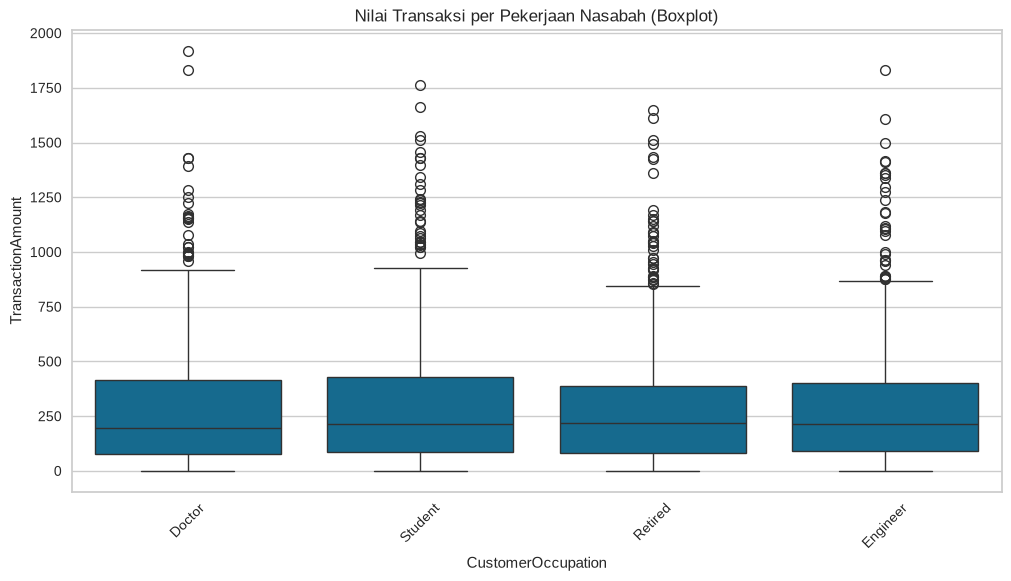

In [9]:
# Visualisasi yang lebih informatif (Opsional Advanced 1)


plt.figure(figsize=(12, 6))

# Buat visualisasi boxplot untuk melihat sebaran 'TransactionAmount' (y) berdasarkan 'CustomerOccupation' (x)
sns.boxplot(x='CustomerOccupation', y='TransactionAmount', data=df)

plt.title("Nilai Transaksi per Pekerjaan Nasabah (Boxplot)")

# Putar label sumbu-x agar tidak tumpang tindih
plt.xticks(rotation=45)

plt.show()


# -----------------------------------------------------------------
# (TANTANGAN OPSIONAL)
# -----------------------------------------------------------------
# Sekarang, bagaimana jika kita juga ingin melihat kepadatan distribusi data di setiap kategori?
# Coba buat visualisasi lain di bawah ini, misalnya 'violinplot' (sns.violinplot) dengan parameter yang sama.

## 3. Data Cleaning & Preprocessing


In [10]:
# Mengecek dataset menggunakan isnull().sum()


df.isnull().sum()



TransactionID              29
AccountID                  21
TransactionAmount          26
PreviousTransactionDate    28
TransactionType            30
Location                   30
DeviceID                   30
IP Address                 20
MerchantID                 23
Channel                    27
CustomerAge                18
CustomerOccupation         23
TransactionDuration        26
LoginAttempts              21
AccountBalance             27
TransactionDate            24
dtype: int64

In [11]:
# Mengecek dataset menggunakan duplicated().sum()


df.duplicated().sum()



np.int64(21)

In [12]:
# Menangani data yang hilang.


df.dropna(inplace=True)

# Cek kembali dataset menggunakan isnull().sum()
df.isnull().sum()



TransactionID              0
AccountID                  0
TransactionAmount          0
PreviousTransactionDate    0
TransactionType            0
Location                   0
DeviceID                   0
IP Address                 0
MerchantID                 0
Channel                    0
CustomerAge                0
CustomerOccupation         0
TransactionDuration        0
LoginAttempts              0
AccountBalance             0
TransactionDate            0
dtype: int64

In [13]:
# Menghapus data duplikat.


df.drop_duplicates(inplace=True)

# Cek kembali dataset menggunakan duplicated().sum()
df.duplicated().sum()



np.int64(0)

In [14]:


# Buat list comprehension untuk memfilter nama kolom.
#    - Iterasi melalui semua nama kolom (col).
#    - Cek apakah 'id', 'ip', atau 'date' ada di nama kolom.
#    - Gunakan .lower() untuk membuat perbandingan case-insensitive (mengabaikan besar/kecil).

cols_to_drop = [col for col in df.columns if
                'id' in col.lower() or
                'ip' in col.lower() or
                'date' in col.lower()]

# Gunakan fungsi .drop() untuk menghapus kolom-kolom yang ada di 'cols_to_drop'.
df = df.drop(columns=cols_to_drop)

df.head()



,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68


In [15]:
# Melakukan feature encoding menggunakan LabelEncoder() untuk fitur kategorikal.


# Pilih semua kolom yang bertipe 'object' (kategorikal)
categorical_cols = list(df.select_dtypes(include=['object']).columns)

encoders = {}

# Loop melalui setiap kolom kategorikal
for column in categorical_cols:
    label_encoder = LabelEncoder()

    # Terapkan (fit) encoder ke data dan sekaligus ubah (transform) data tersebut
    df[column] = label_encoder.fit_transform(df[column])

    # Simpan encoder
    encoders[column] = label_encoder

df.head()



,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,1,36,0,70.0,0,81.0,1.0,5112.21
1,376.24,1,15,0,68.0,0,141.0,1.0,13758.91
2,126.29,1,23,2,19.0,3,56.0,1.0,1122.35
3,184.50,1,33,2,26.0,3,25.0,1.0,8569.06
5,92.15,1,28,0,18.0,3,172.0,1.0,781.68


In [16]:
# Last checking gunakan columns.tolist() untuk checking seluruh fitur yang ada.


df.columns.tolist()



['TransactionAmount',
 'TransactionType',
 'Location',
 'Channel',
 'CustomerAge',
 'CustomerOccupation',
 'TransactionDuration',
 'LoginAttempts',
 'AccountBalance']

In [17]:
# Melakukan Handling Outlier Data menggunakan metode drop.

for col in numerical_cols:


    # Hitung Kuartil 1 (Q1) dan Kuartil 3 (Q3)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    # Hitung Interquartile Range (IQR)
    IQR = Q3 - Q1

    # Tentukan batas bawah (lower bound) dan batas atas (upper bound)
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Filter DataFrame: Simpan hanya baris di mana nilai 'df[col]' berada DI ANTARA (inklusif) batas bawah dan batas atas.
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]


# Tampilkan statistik deskriptif setelah outlier dihapus
df.describe()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
count,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.0,1945.000000
mean,256.838278,0.771722,21.299743,0.977378,44.693059,1.503342,119.225193,1.0,5100.811913
std,218.370197,0.419830,12.329250,0.804119,17.743453,1.135888,70.600647,0.0,3907.153333
min,0.260000,0.000000,0.000000,0.000000,18.000000,0.000000,10.000000,1.0,102.200000
25%,78.920000,1.000000,11.000000,0.000000,27.000000,0.000000,63.000000,1.0,1488.650000
50%,199.700000,1.000000,21.000000,1.000000,45.000000,1.000000,111.000000,1.0,4693.600000
75%,374.500000,1.000000,32.000000,2.000000,59.000000,3.000000,162.000000,1.0,7659.990000
max,903.190000,1.000000,42.000000,2.000000,80.000000,3.000000,300.000000,1.0,14977.990000


In [18]:
# Melakukan feature scaling menggunakan StandardScaler() untuk fitur numerik.


scaler = StandardScaler()

# Terapkan (fit) scaler ke data dan sekaligus ubah (transform) data tersebut
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

df.head()



,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726


In [19]:
# Melakukan binning data berdasarkan kondisi rentang nilai pada fitur numerik,
# lakukan pada satu sampai dua fitur numerik.


# Tentukan kolom numerik yang ingin Anda kelompokkan
col_to_bin = 'CustomerAge'  # (Isi dengan 'CustomerAge' atau kolom numerik lain)

# Tentukan nama untuk kolom kategori baru
new_col_name = 'AgeGroup'

# Tentukan label untuk 3 grup (Anda dapat menentukan nama label-nya sendiri)
# Mulai dari rendah --> sedang --> tinggi
bin_labels = ['Young', 'Adult', 'Senior']

# Gunakan 'pd.qcut' untuk membagi data menjadi 3 kelompok
df[new_col_name] = pd.qcut(df[col_to_bin], q=3, labels=bin_labels, duplicates='drop')

# Lakukan Label Encoding pada kolom baru ini agar menjadi numerik
label_encoder = LabelEncoder()
df[new_col_name] = label_encoder.fit_transform(df[new_col_name])

# Simpan encoder dan tambahkan nama kolom baru ke 'categorical_cols'
encoders[new_col_name] = label_encoder
categorical_cols.extend([new_col_name])

df.head()



,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918,1
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531,1
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513,2
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895,2
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726,2


## 4. K-Means Clustering


In [20]:
# Kode harus digunakan dan dilarang menambahkan syntax lainnya pada cell ini.


# Buat salinan (copy) dari 'df' ke variabel 'df_used'
df_used = df.copy()

# Tampilkan ringkasan statistik dari DataFrame 'df'
df_used.describe()



,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup
count,1.945000e+03,1945.000000,1945.000000,1945.000000,1.945000e+03,1945.000000,1.945000e+03,1945.0,1.945000e+03,1945.000000
mean,-8.402305e-17,0.771722,21.299743,0.977378,-1.269479e-16,1.503342,2.557223e-17,0.0,-6.027740e-17,1.015424
std,1.000257e+00,0.419830,12.329250,0.804119,1.000257e+00,1.135888,1.000257e+00,0.0,1.000257e+00,0.820123
min,-1.175271e+00,0.000000,0.000000,0.000000,-1.504776e+00,0.000000,-1.547483e+00,0.0,-1.279678e+00,0.000000
25%,-8.149648e-01,1.000000,11.000000,0.000000,-9.974163e-01,0.000000,-7.965883e-01,0.0,-9.247374e-01,0.000000
50%,-2.617251e-01,1.000000,21.000000,1.000000,1.730327e-02,1.000000,-1.165330e-01,0.0,-1.042490e-01,1.000000
75%,5.389562e-01,1.000000,32.000000,2.000000,8.065296e-01,3.000000,6.060257e-01,0.0,6.551666e-01,2.000000
max,2.960651e+00,1.000000,42.000000,2.000000,1.990369e+00,3.000000,2.561185e+00,0.0,2.528623e+00,2.000000


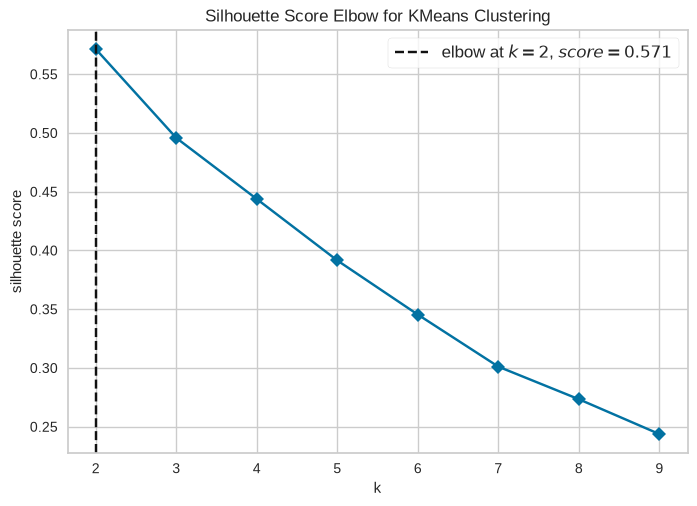

<Axes: title={'center': 'Silhouette Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='silhouette score'>

In [21]:
# Melakukan visualisasi Elbow Method menggunakan KElbowVisualizer()

model = KMeans()


#  - Masukkan 'model' yang akan digunakan
#  - Tentukan 'metric' evaluasi
visualizer = KElbowVisualizer(model,
                       k=(2,10),
                       metric='silhouette',
                       timings=False)

# Jalankan (fit) visualizer pada data
visualizer.fit(df)

# Tampilkan plot
visualizer.show()



In [22]:
# Menggunakan algoritma K-Means Clustering


model = KMeans(n_clusters=2, random_state=42)

# Latih (fit) model dengan data Anda (df)
model.fit(df)



KMeans(n_clusters=2, random_state=42)

In [23]:
# Menyimpan model menggunakan joblib


# Simpan model clustering yang sudah dilatih
joblib.dump(model, "model_clustering.h5")



['model_clustering.h5']

In [24]:
# Menghitung dan menampilkan nilai Silhouette Score.


labels = model.labels_

score = silhouette_score(df, labels)

# Cetak skornya
print("Silhouette Score:", score)



Silhouette Score: 0.5720739691275379


/home/claude/colabenv/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


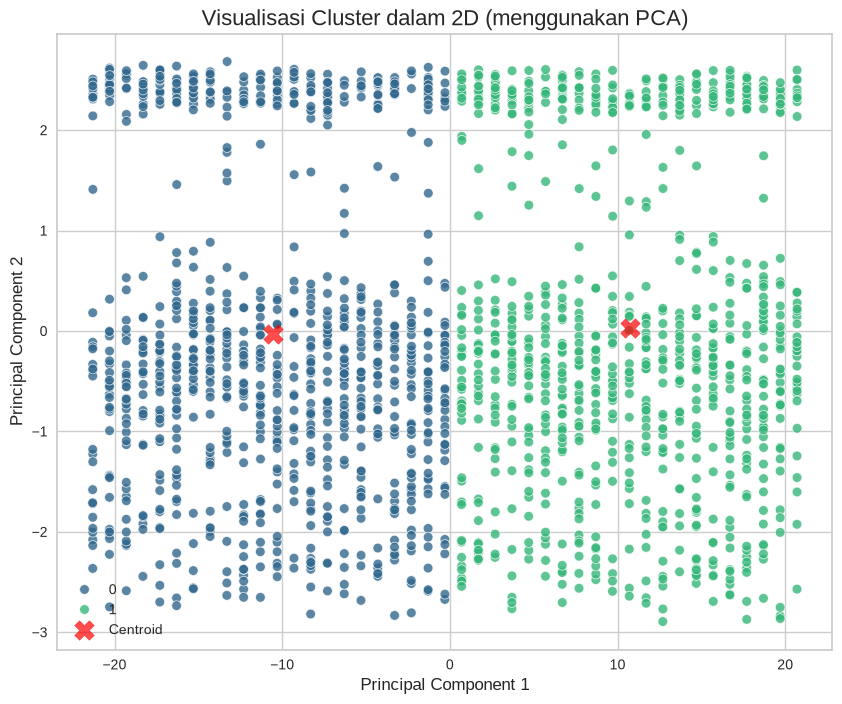

In [25]:
# Membuat visualisasi hasil clustering


pca = PCA(n_components=2)

# Terapkan (fit) PCA ke data 'df' dan transformasikan data tersebut
df_pca = pca.fit_transform(df)

# Buat DataFrame baru 'df_pca' dari hasil transformasi
df_pca = pd.DataFrame(data=df_pca, columns=['Principal Component 1', 'Principal Component 2'])

# Tambahkan kolom 'Cluster' ke 'df_pca' menggunakan 'labels'(variabel dari hasil 'kmeans.labels_' sebelumnya)
df_pca['Cluster'] = labels

# Buat scatter plot menggunakan Seaborn
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='Principal Component 1',
    y='Principal Component 2',
    hue='Cluster',  # Warnai titik berdasarkan kolom 'Cluster'
    palette=sns.color_palette("viridis", n_colors=2),
    data=df_pca,
    legend="full",
    alpha=0.8
)


plt.title('Visualisasi Cluster dalam 2D (menggunakan PCA)', fontsize=16)
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
centers = pca.transform(model.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.7, marker='X', label='Centroid')
plt.legend()
plt.show()

In [26]:
# Membangun model menggunakan PCA.


pca = PCA(n_components=2)

# Terapkan (fit) PCA ke data 'df_used' dan transformasikan data tersebut
df_pca_array = pca.fit_transform(df_used)

# Buat DataFrame baru 'data_final' dari hasil array PCA
data_final = pd.DataFrame(data=df_pca_array, columns=['PCA1', 'PCA2'])

kmeans_pca = KMeans(n_clusters=2, random_state=42)

# Latih (fit) model KMeans BARU ini HANYA pada 'data_final'
kmeans_pca.fit(data_final)



KMeans(n_clusters=2, random_state=42)

In [27]:
# Simpan model PCA sebagai perbandingan dengan menjalankan cell code ini joblib.dump(model,"PCA_model_clustering.h5")


# Pastikan yang disimpan model yang sudah melalui .fit berdasarkan dataset yang sudah dilakukan PCA
joblib.dump(kmeans_pca, "PCA_model_clustering.h5")



['PCA_model_clustering.h5']

## 5. Cluster Interpretation


In [28]:
# Menampilkan analisis deskriptif minimal mean, min dan max untuk fitur numerik.
# pastikan output menghasilkan agregasi dan groupby bersamaan dengan mean, min, dan max.


# Tambahkan kolom 'Cluster' baru berupa 'labels' (variabel dari 'kmeans.labels_' sebelumnya)
df_used['Cluster'] = labels

# Kelompokkan (groupby) 'df_used' berdasarkan 'Cluster' dan hitung agregasi untuk 'numerical_cols'.
agg_summary = df_used.groupby('Cluster')[numerical_cols].agg(['mean', 'min', 'max']).round(2).T

# Tampilkan hasil ringkasan
display(agg_summary)



Cluster                      0     1
TransactionAmount   mean -0.01  0.01
                    min  -1.17 -1.18
                    max   2.96  2.90
CustomerAge         mean  0.02 -0.02
                    min  -1.50 -1.50
                    max   1.99  1.99
TransactionDuration mean  0.03 -0.03
                    min  -1.55 -1.55
                    max   2.56  2.55
LoginAttempts       mean  0.00  0.00
                    min   0.00  0.00
                    max   0.00  0.00
AccountBalance      mean  0.01 -0.01
                    min  -1.28 -1.28
                    max   2.52  2.53

## Menjelaskan karakteristik tiap cluster berdasarkan rentangnya sebelum **Inverse** (masih dalam kondisi **Scaled**).
1. **CLUSTER 0: (Transaksi di Kota Kelompok A–L)**:
  - **Rata-rata (mean) TransactionAmount:** -0.01 (min -1.17, max 2.96) | setelah inverse ≈ 255.55
  - **Rata-rata (mean) CustomerAge:** 0.02 (min -1.50, max 1.99) | setelah inverse ≈ 45.06
  - **Rata-rata (mean) TransactionDuration:** 0.03 (min -1.55, max 2.56) | setelah inverse ≈ 121.12
  - **Rata-rata (mean) LoginAttempts:** 0.00 (min 0.00, max 0.00) | setelah inverse = 1.00
  - **Rata-rata (mean) AccountBalance:** 0.01 (min -1.28, max 2.52) | setelah inverse ≈ 5,142.17
  - **Analisis:** Seluruh rata-rata fitur numerik pada cluster ini berada sangat dekat dengan 0 (rata-rata seluruh data setelah scaling), sehingga profil nilai transaksi, usia, durasi, dan saldo nasabahnya tergolong rata-rata. Cluster ini beranggotakan 980 transaksi dan terbentuk dari kota-kota dengan kode encoding rendah (Albuquerque sampai Louisville). Karena `Location` di-*label encode* menjadi angka 0 sampai 42 dan tidak ikut distandarisasi, fitur ini mendominasi jarak K-Means sehingga pemisahan cluster pada dasarnya mengikuti kode kota, bukan perbedaan perilaku transaksi.
2. **CLUSTER 1: (Transaksi di Kota Kelompok M–W)**:
  - **Rata-rata (mean) TransactionAmount:** 0.01 (min -1.18, max 2.90) | setelah inverse ≈ 258.15
  - **Rata-rata (mean) CustomerAge:** -0.02 (min -1.50, max 1.99) | setelah inverse ≈ 44.33
  - **Rata-rata (mean) TransactionDuration:** -0.03 (min -1.55, max 2.55) | setelah inverse ≈ 117.30
  - **Rata-rata (mean) LoginAttempts:** 0.00 (min 0.00, max 0.00) | setelah inverse = 1.00
  - **Rata-rata (mean) AccountBalance:** -0.01 (min -1.28, max 2.53) | setelah inverse ≈ 5,058.81
  - **Analisis:** Profil numerik cluster ini nyaris sama dengan Cluster 0 (selisih rata-rata hanya sekitar 0.02 sampai 0.06 satuan standar deviasi). Cluster ini beranggotakan 965 transaksi dari kota dengan kode encoding tinggi (Memphis sampai Washington). Hasilnya menunjukkan bahwa fitur numerik tidak memisahkan nasabah ke dalam kelompok yang berbeda. Perlu dicatat juga bahwa `LoginAttempts` bernilai konstan (1) pada kedua cluster karena penghapusan outlier dengan IQR pada kolom ini (Q1 = Q3 = 1) membuang seluruh transaksi dengan percobaan login lebih dari satu.


## 6. Export Results


In [29]:
# Pastikan nama kolom clustering sudah diubah menjadi Target


df_used.rename(columns={"Cluster": "Target"}, inplace=True)

df_used.head()



,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup,Target
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918,1,1
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531,1,0
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513,2,1
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895,2,1
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726,2,1


In [30]:
# Simpan Data


df_used.to_csv('data_clustering.csv', index=False)



In [31]:
# inverse dataset ke rentang normal untuk numerikal

df_inverse = df_used.copy()


# Gunakan 'scaler' untuk mengembalikan 'numerical_cols' ke nilai aslinya.
df_inverse[numerical_cols] = scaler.inverse_transform(df_inverse[numerical_cols])

df_inverse.head()



,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup,Target
0,14.09,1,36,0,70.0,0,81.0,1.0,5112.21,1,1
1,376.24,1,15,0,68.0,0,141.0,1.0,13758.91,1,0
2,126.29,1,23,2,19.0,3,56.0,1.0,1122.35,2,1
3,184.50,1,33,2,26.0,3,25.0,1.0,8569.06,2,1
5,92.15,1,28,0,18.0,3,172.0,1.0,781.68,2,1


In [32]:
# inverse dataset yang sudah diencode ke kategori aslinya.


for column in categorical_cols:
    # Ambil encoder yang tepat untuk 'column' dari dictionary 'encoders'
    encoder = encoders[column]

    # Gunakan scaler untuk mengembalikan (inverse) kolom tersebut
    df_inverse[column] = encoder.inverse_transform(df_inverse[column].astype(int))

df_inverse.head()

### SELESEI CODE ###

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,Senior,1
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,Senior,0
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,Young,1
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,Young,1
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,Young,1


In [33]:
# Lakukan analisis deskriptif minimal mean, min dan max untuk fitur numerik dan mode untuk kategorikal seperti pada basic tetapi menggunakan data yang sudah diinverse.
# pastikan output menghasilkan agregasi dan groupby bersamaan dengan mean, min, dan max kembali setelah melakukan inverse.


# Kelompokkan (groupby) 'df_inverse' berdasarkan 'Target' dan hitung agregasi untuk 'numerical_cols'.
agg_summary_num = df_inverse.groupby('Target')[numerical_cols].agg(['mean', 'min', 'max']).round(2).T

# Kelompokkan (groupby) 'df_inverse' berdasarkan 'Target' dan hitung agregasi untuk 'categorical_cols'.
#   - Hitung agregasi (agg) 'mode' (nilai yang paling sering muncul).
#   - (Kita gunakan 'lambda x: x.mode()[0]' untuk mengambil nilai mode pertama)
agg_summary_cat = df_inverse.groupby('Target')[categorical_cols].agg(lambda x: x.mode()[0]).round(2).T


# Tampilkan kedua hasil ringkasan
display(agg_summary_num)
display(agg_summary_cat)

Target                           0         1
TransactionAmount   mean    255.55    258.15
                    min       0.32      0.26
                    max     903.19    889.01
CustomerAge         mean     45.06     44.33
                    min      18.00     18.00
                    max      80.00     80.00
TransactionDuration mean    121.12    117.30
                    min      10.00     10.00
                    max     300.00    299.00
LoginAttempts       mean      1.00      1.00
                    min       1.00      1.00
                    max       1.00      1.00
AccountBalance      mean   5142.17   5058.81
                    min     117.98    102.20
                    max   14942.78  14977.99

Target,0,1
TransactionType,Debit,Debit
Location,Charlotte,Tucson
Channel,Branch,Branch
CustomerOccupation,Doctor,Student
AgeGroup,Adult,Young


## Menjelaskan karakteristik tiap cluster berdasarkan rentangnya setelah **Inverse**.
1. **Cluster 0: (Transaksi di Kota Kelompok A–L)**:
  - **Rata-rata (mean) TransactionAmount:** -0.01 → **255.55** (min 0.32, max 903.19)
  - **Rata-rata (mean) CustomerAge:** 0.02 → **45.06** tahun (min 18, max 80)
  - **Rata-rata (mean) TransactionDuration:** 0.03 → **121.12** detik (min 10, max 300)
  - **Rata-rata (mean) AccountBalance:** 0.01 → **5,142.17** (min 117.98, max 14,942.78)
  - **Modus kategorikal:** TransactionType = Debit, Location = Charlotte, Channel = Branch, CustomerOccupation = Doctor, AgeGroup = Adult
  - **Analisis:** Cluster ini berisi 980 transaksi yang seluruhnya terjadi di 22 kota, dari Albuquerque sampai Louisville (urutan abjad awal). Nasabahnya berusia rata-rata 45 tahun dengan nilai transaksi rata-rata sekitar 255 dan saldo rata-rata sekitar 5,142. Komposisi kategorinya berimbang: sekitar 78% transaksi Debit, kanal terbanyak Branch (35.8%), dan pekerjaan terbanyak Doctor (27.6%), tetapi selisihnya dengan pekerjaan lain hanya beberapa poin persentase sehingga tidak bisa dianggap karakteristik yang kuat. Rekomendasi: karena perilaku transaksinya tergolong umum, nasabah di cluster ini dapat ditawari produk perbankan standar (tabungan, kartu debit, layanan cabang) dan tidak memerlukan perlakuan khusus berdasarkan pola transaksi.
2. **Cluster 1: (Transaksi di Kota Kelompok M–W)**:
  - **Rata-rata (mean) TransactionAmount:** 0.01 → **258.15** (min 0.26, max 889.01)
  - **Rata-rata (mean) CustomerAge:** -0.02 → **44.33** tahun (min 18, max 80)
  - **Rata-rata (mean) TransactionDuration:** -0.03 → **117.30** detik (min 10, max 299)
  - **Rata-rata (mean) AccountBalance:** -0.01 → **5,058.81** (min 102.20, max 14,977.99)
  - **Modus kategorikal:** TransactionType = Debit, Location = Tucson, Channel = Branch, CustomerOccupation = Student, AgeGroup = Young
  - **Analisis:** Cluster ini berisi 965 transaksi dari 21 kota, dari Memphis sampai Washington. Rata-rata nilai transaksi (258.15), usia (44.33), durasi (117.30 detik), dan saldo (5,058.81) hampir sama dengan Cluster 0. Perbedaan kecil terlihat pada modus pekerjaan (Student, 27.5%) dan kelompok usia (Young, 35.5%), namun selisihnya hanya sekitar 2 sampai 4 poin persentase terhadap Cluster 0 sehingga sebaiknya tidak ditafsirkan sebagai segmen yang berbeda. Rekomendasi: perlakukan serupa dengan Cluster 0.

**Kesimpulan:** Dua cluster yang terbentuk hampir tidak dapat dibedakan dari sisi perilaku nasabah (nilai transaksi, usia, durasi, saldo, tipe transaksi, kanal, dan pekerjaan). Satu-satunya pembeda nyata adalah kelompok kota, yaitu kota A–L untuk Cluster 0 dan M–W untuk Cluster 1. Hal ini berasal dari proses pra-pemrosesan yang diwajibkan: `Location` di-*label encode* menjadi 0 sampai 42 dan tidak distandarisasi, sehingga skalanya jauh lebih besar daripada fitur numerik yang sudah distandarisasi dan menguasai perhitungan jarak K-Means. Skor silhouette yang tinggi (0.572) pada k = 2 mencerminkan pemisahan yang rapi berdasarkan kode kota, bukan segmentasi perilaku yang bermakna secara bisnis. Untuk segmentasi yang lebih informatif, `Location` sebaiknya tidak dipakai sebagai fitur clustering atau diskalakan terlebih dahulu.


In [34]:
# Periksa kembali data yang telah di-inverse.


df_inverse.head()



,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,Senior,1
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,Senior,0
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,Young,1
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,Young,1
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,Young,1


In [35]:
# Simpan Data Inverse


df_inverse.to_csv('data_clustering_inverse.csv', index=False)

